# Example 1 — Run a workflow & render its DAG

A minimal two-rule Snakemake workflow, driven from the notebook. We run it, then visualize the DAG with Graphviz.

> Make sure the `snakemake-tutorial` conda env is active and selected as this notebook's kernel.

## 1. Inspect the Snakefile

In [1]:
print(open("Snakefile").read())

# Example 1 — a minimal two-rule workflow
#
# rule all -> transform -> create
# Produces greeting.txt and then an upper-cased version.

rule all:
    input:
        "shout.txt",

rule create:
    output:
        "greeting.txt",
    shell:
        "echo 'hello river' > {output}"

rule transform:
    input:
        "greeting.txt",
    output:
        "shout.txt",
    shell:
        "tr '[:lower:]' '[:upper:]' < {input} > {output}"



## 2. Dry run (`-n`)

See what Snakemake *would* do without executing anything.

In [2]:
!snakemake -n -p --cores 1


SNAKEMAKE
  Date: 2026-11-23 15:52:32
  Workflow ID: 2f180be0-683d-4114-b760-6824878e4eae
  Platform: macOS-15.8.1-x86_64-i386-64bit-Mach-O
  Host: caterpillar.psc.edu
  User: icaoberg
  Snakemake version: 9.24.0
  Python version: 3.14.10 | packaged by conda-forge | (main, Oct 26 2026, 11:53:01) [Clang 20.1.8 ]
  Command: /opt/anaconda3/envs/snakemake-tutorial/bin/snakemake -n -p --cores 1
  Snakefile: /Users/icaoberg/Documents/code/snakemake-tutorial/example1/Snakefile
  Base directory: /Users/icaoberg/Documents/code/snakemake-tutorial/example1
  Run directory: /Users/icaoberg/Documents/code/snakemake-tutorial/example1
  Working directory: /Users/icaoberg/Documents/code/snakemake-tutorial/example1
  Config file(s): []
  Config MD5: 99914b932bd37a50b983c5e7c90ae93b

Building DAG of jobs...
Job stats:
job          count
---------  -------
create           1
transform        1
all              1
total            3


[Mon Nov 23 15:52:32 2026]
rule create:
    output: greeting.txt
    jo

## 3. Execute the workflow

In [3]:
!snakemake --cores 1
print("---")
print(open("shout.txt").read())

Assuming unrestricted shared filesystem usage.

SNAKEMAKE
  Date: 2026-11-23 15:52:51
  Workflow ID: d2fb3576-bf5f-42aa-b5a7-b29995995b59
  Platform: macOS-15.8.1-x86_64-i386-64bit-Mach-O
  Host: caterpillar.psc.edu
  User: icaoberg
  Snakemake version: 9.24.0
  Python version: 3.14.10 | packaged by conda-forge | (main, Oct 26 2026, 11:53:01) [Clang 20.1.8 ]
  Command: /opt/anaconda3/envs/snakemake-tutorial/bin/snakemake --cores 1
  Snakefile: /Users/icaoberg/Documents/code/snakemake-tutorial/example1/Snakefile
  Base directory: /Users/icaoberg/Documents/code/snakemake-tutorial/example1
  Run directory: /Users/icaoberg/Documents/code/snakemake-tutorial/example1
  Working directory: /Users/icaoberg/Documents/code/snakemake-tutorial/example1
  Config file(s): []
  Config MD5: 99914b932bd37a50b983c5e7c90ae93b

Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 1 (use --cores to define parallelism)
Rules claiming more threads will be scaled down.
Job stats:
job          count
-

## 4. Render the DAG as SVG

`--dag` emits Graphviz dot; pipe it through `dot` and display inline.

Building DAG of jobs...


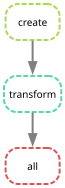

In [4]:
from IPython.display import SVG, display

!snakemake --dag | dot -Tsvg > dag.svg
display(SVG("dag.svg"))